# 06 - EDA thị trường cryptocurrency

EDA này trả lời bốn câu hỏi: dữ liệu giá phủ đến đâu, giá thay đổi theo thời gian thế nào,
lợi suất/rủi ro có đặc điểm gì và cơ cấu vốn hóa tại cùng một ngày ra sao. Hình không dùng
để suy luận quan hệ với vĩ mô; phần đó nằm ở notebook 08.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.insert(0, str(Path.cwd() / "scripts"))
from common import TABLES, FIGURES, QUALITY, ensure_output_dirs, write_csv_atomic, write_json_atomic
ensure_output_dirs()
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 180, "font.family": "DejaVu Sans"})

crypto = pd.read_csv(TABLES / "fact_crypto_daily.csv.gz", parse_dates=["date"], low_memory=False)
market = pd.read_csv(TABLES / "fact_market_daily.csv.gz", parse_dates=["date"], low_memory=False)
dim = pd.read_csv(
    TABLES / "dim_coin.csv",
    parse_dates=["raw_first_date", "raw_last_date", "price_first_date", "price_last_date", "market_cap_as_of_date"],
)
btc = crypto.loc[crypto["ticker"].eq("BTC")].sort_values("date")
eth = crypto.loc[crypto["ticker"].eq("ETH")].sort_values("date")

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / name, bbox_inches="tight")
    plt.show()
    plt.close(fig)

## H01 - Độ phủ lịch sử giá

**Vì sao dùng timeline ngang:** biến cần so sánh là khoảng bắt đầu-kết thúc theo từng coin.
Timeline biểu diễn trực tiếp khoảng thời gian và cho thấy vì sao phải chọn cửa sổ chung khi
so sánh. Bar theo số ngày sẽ làm mất vị trí lịch sử của khoảng dữ liệu.

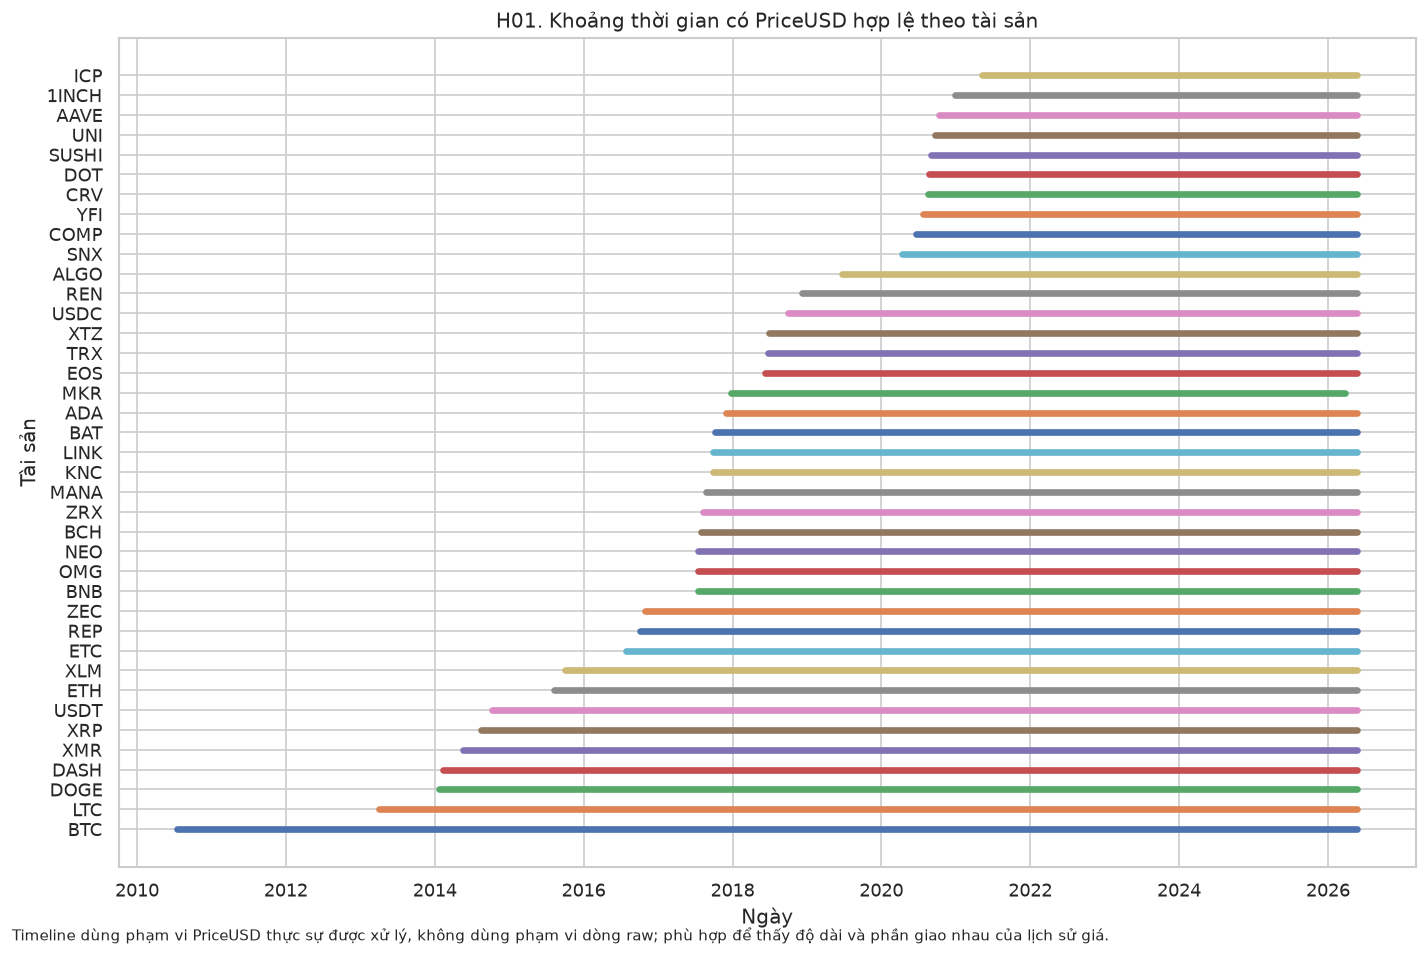

In [2]:
coverage = dim.loc[
    dim["has_price_history"].eq(True) & dim["price_first_date"].notna(),
    ["ticker", "price_first_date", "price_last_date"],
].sort_values("price_first_date")

fig, ax = plt.subplots(figsize=(12, 8))
for y, row in enumerate(coverage.itertuples(index=False)):
    ax.plot([row.price_first_date, row.price_last_date], [y, y], lw=4, solid_capstyle="round")
ax.set_yticks(range(len(coverage)))
ax.set_yticklabels(coverage["ticker"])
ax.set_title("H01. Khoảng thời gian có PriceUSD hợp lệ theo tài sản")
ax.set_xlabel("Ngày")
ax.set_ylabel("Tài sản")
fig.text(
    .01, .01,
    "Timeline dùng phạm vi PriceUSD thực sự được xử lý, không dùng phạm vi dòng raw; phù hợp để thấy độ dài và phần giao nhau của lịch sử giá.",
    fontsize=9,
)
save(fig, "H01_do_phu_gia_crypto.png")

## H02 - Giá BTC và ETH theo thời gian

**Vì sao dùng line và trục log:** giá là chuỗi thời gian liên tục, cần giữ thứ tự ngày.
BTC/ETH trải qua nhiều bậc độ lớn nên log scale giúp quan sát cả giai đoạn sớm và muộn.
Hình mô tả xu hướng giá, không dùng để kết luận tương quan vì hai chuỗi cùng có trend.

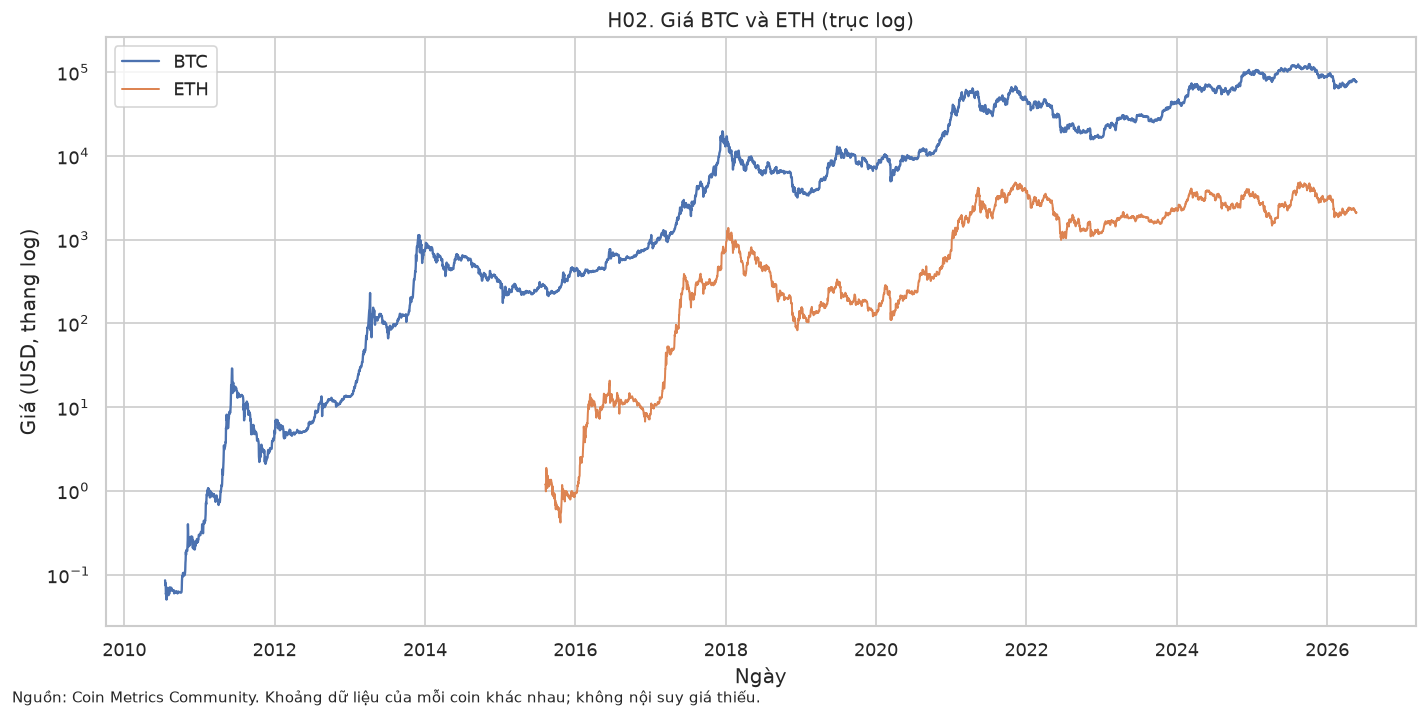

In [3]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(btc.date, btc.price_usd, label="BTC", linewidth=1.4)
ax.plot(eth.date, eth.price_usd, label="ETH", linewidth=1.2)
ax.set_yscale("log")
ax.set_title("H02. Giá BTC và ETH (trục log)")
ax.set_xlabel("Ngày"); ax.set_ylabel("Giá (USD, thang log)"); ax.legend()
fig.text(.01, .01, "Nguồn: Coin Metrics Community. Khoảng dữ liệu của mỗi coin khác nhau; không nội suy giá thiếu.", fontsize=9)
save(fig, "H02_gia_btc_eth_log.png")

## H03 - Phân phối lợi suất ngày

**Vì sao dùng histogram và KDE:** cần quan sát độ tập trung, bất đối xứng và đuôi phân phối.
Trục x chỉ giới hạn để phần trung tâm đọc được; thống kê/kiểm định vẫn dùng toàn bộ dữ liệu,
không cắt hay xóa sự kiện cực đoan.

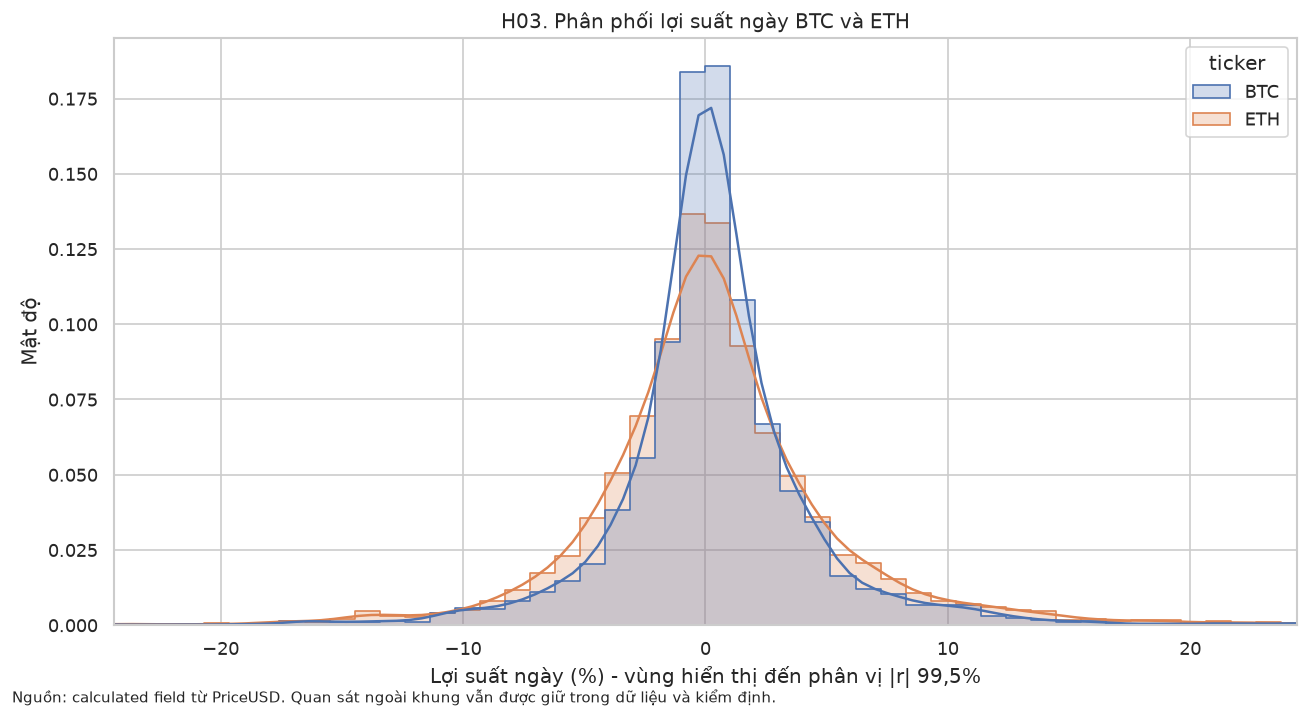

In [4]:
returns = pd.concat([
    btc[["daily_return_pct"]].assign(ticker="BTC"),
    eth[["daily_return_pct"]].assign(ticker="ETH"),
]).dropna()
display_limit = returns.daily_return_pct.abs().quantile(.995)
fig, ax = plt.subplots(figsize=(11, 6))
sns.histplot(data=returns, x="daily_return_pct", hue="ticker", bins=100, stat="density", common_norm=False, element="step", kde=True, ax=ax)
ax.set_xlim(-display_limit, display_limit)
ax.set_title("H03. Phân phối lợi suất ngày BTC và ETH")
ax.set_xlabel("Lợi suất ngày (%) - vùng hiển thị đến phân vị |r| 99,5%")
ax.set_ylabel("Mật độ")
fig.text(.01, .01, "Nguồn: calculated field từ PriceUSD. Quan sát ngoài khung vẫn được giữ trong dữ liệu và kiểm định.", fontsize=9)
save(fig, "H03_phan_phoi_loi_suat_ngay.png")

## H04 - QQ plot lợi suất BTC

**Vì sao dùng QQ plot:** histogram phụ thuộc bin; QQ plot so trực tiếp phân vị thực nghiệm
với chuẩn. Độ lệch ở hai đầu cho thấy mô hình chuẩn không mô tả tốt tail risk, nhưng bản thân
QQ plot không xác định nguyên nhân của các cú sốc.

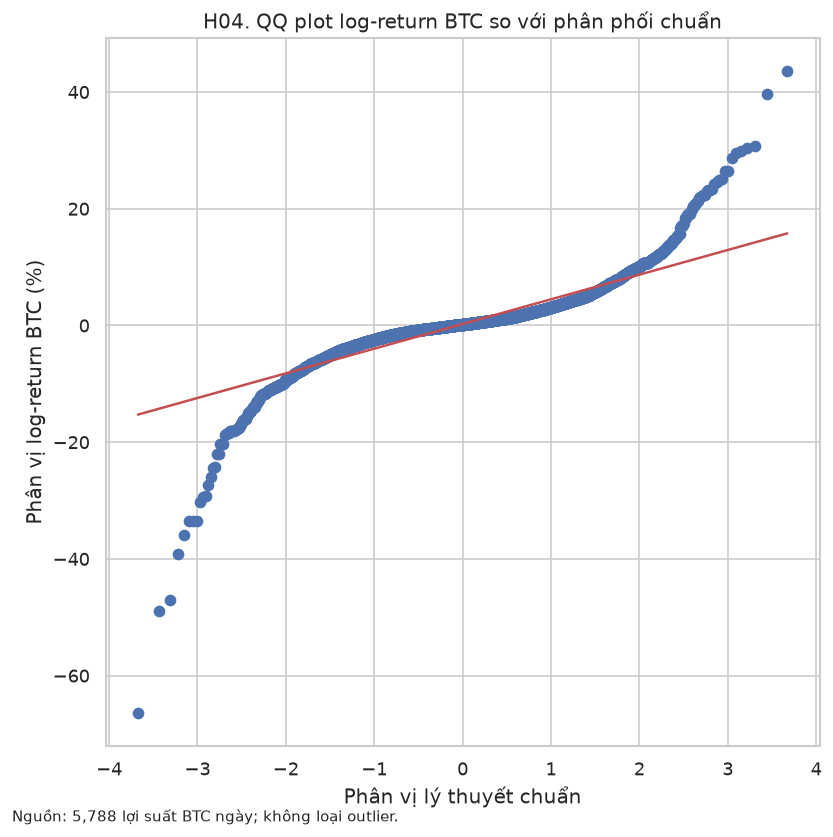

In [5]:
btc_ret = btc.log_return.dropna() * 100
fig, ax = plt.subplots(figsize=(7, 7))
stats.probplot(btc_ret, dist="norm", plot=ax)
ax.set_title("H04. QQ plot log-return BTC so với phân phối chuẩn")
ax.set_xlabel("Phân vị lý thuyết chuẩn"); ax.set_ylabel("Phân vị log-return BTC (%)")
fig.text(.01, .01, f"Nguồn: {len(btc_ret):,} lợi suất BTC ngày; không loại outlier.", fontsize=9)
save(fig, "H04_qq_plot_btc.png")

## H05 - Drawdown BTC

**Vì sao dùng area chart dưới mốc 0:** drawdown đo khoảng cách với đỉnh lũy kế và luôn không
dương. Vùng tô làm rõ độ sâu/thời lượng các giai đoạn giảm; không thay thế xác suất thua lỗ tương lai.

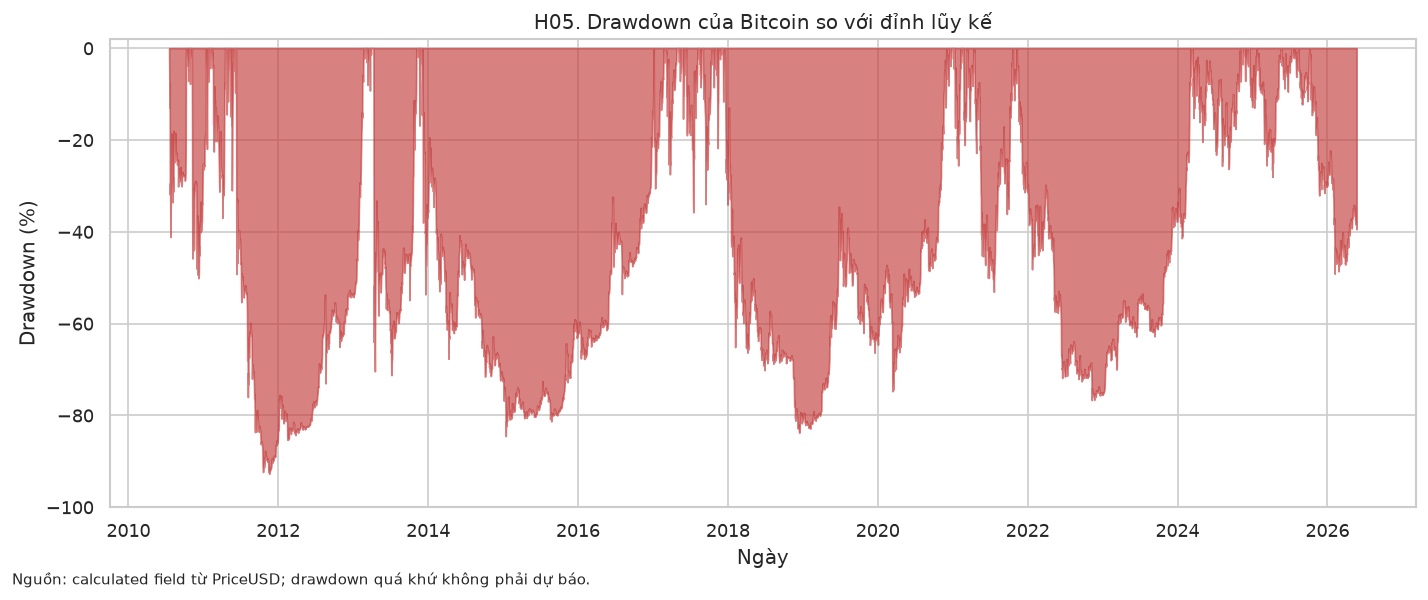

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(btc.date, btc.drawdown_pct, 0, color="#C43D3D", alpha=.65)
ax.set_title("H05. Drawdown của Bitcoin so với đỉnh lũy kế")
ax.set_xlabel("Ngày"); ax.set_ylabel("Drawdown (%)"); ax.set_ylim(min(-100, btc.drawdown_pct.min()*1.05), 2)
fig.text(.01, .01, "Nguồn: calculated field từ PriceUSD; drawdown quá khứ không phải dự báo.", fontsize=9)
save(fig, "H05_drawdown_btc.png")

## H06 - Phân phối biến động theo năm

**Vì sao dùng boxplot:** mỗi năm chứa nhiều quan sát volatility 30 ngày; boxplot so sánh
trung vị, IQR và đuôi mà không giả định phân phối chuẩn. Năm 2026 là năm chưa hoàn chỉnh nên
được gắn nhãn riêng và không dùng để kết luận xu hướng năm đầy đủ.

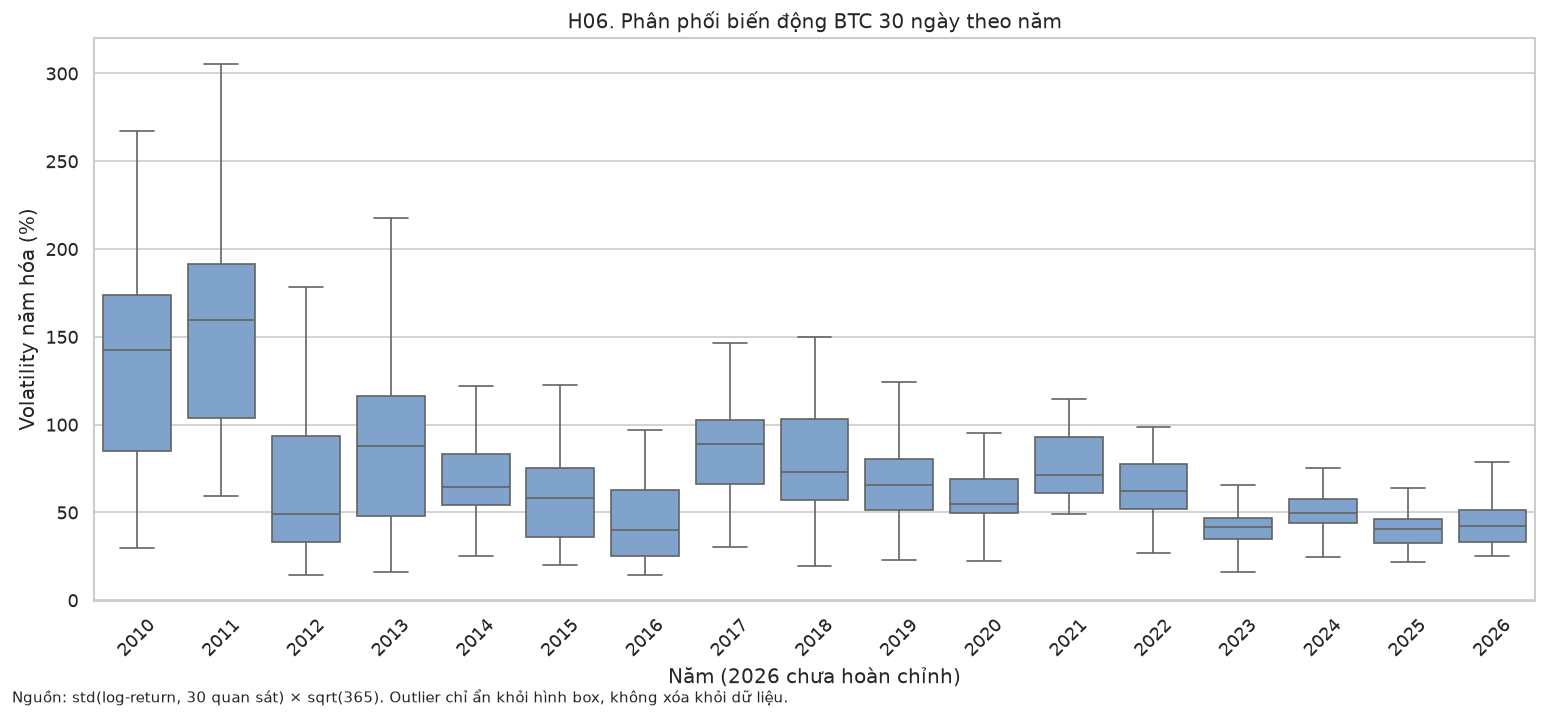

In [7]:
vol = btc.dropna(subset=["volatility_30d_annualized_pct"]).copy()
vol["year"] = vol.date.dt.year.astype(str)
fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=vol, x="year", y="volatility_30d_annualized_pct", color="#73A2D6", showfliers=False, ax=ax)
ax.set_title("H06. Phân phối biến động BTC 30 ngày theo năm")
ax.set_xlabel("Năm (2026 chưa hoàn chỉnh)"); ax.set_ylabel("Volatility năm hóa (%)")
ax.tick_params(axis="x", rotation=45)
fig.text(.01, .01, "Nguồn: std(log-return, 30 quan sát) × sqrt(365). Outlier chỉ ẩn khỏi hình box, không xóa khỏi dữ liệu.", fontsize=9)
save(fig, "H06_bien_dong_btc_theo_nam.png")

## H07 - Vốn hóa tại cùng một ngày

**Vì sao dùng bar ngang và trục log:** đây là so sánh thứ hạng trên một lát cắt thời gian
chung. Trục log giữ khả năng đọc coin nhỏ khi vốn hóa lệch nhiều bậc. Coin thiếu dữ liệu đúng
ngày không được thay bằng vốn hóa cũ và không xuất hiện trong xếp hạng.

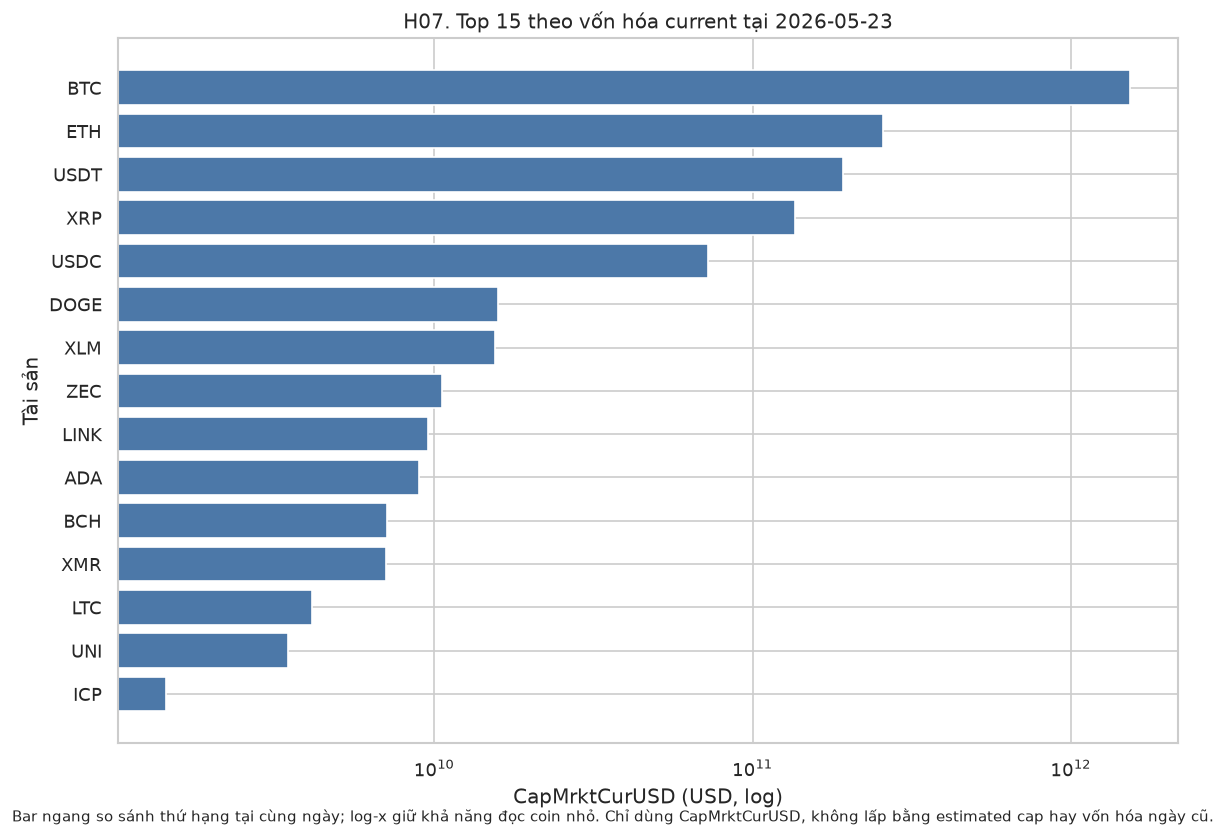

In [8]:
as_of = market.loc[market["market_cap_current_usd"].notna(), "date"].max()
top = (
    market.loc[
        market["date"].eq(as_of) & market["market_cap_current_usd"].notna(),
        ["ticker", "market_cap_current_usd"],
    ]
    .sort_values("market_cap_current_usd", ascending=False)
    .head(15)
    .sort_values("market_cap_current_usd")
)
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["ticker"], top["market_cap_current_usd"], color="#4C78A8")
ax.set_xscale("log")
ax.set_title(f"H07. Top 15 theo vốn hóa current tại {as_of:%Y-%m-%d}")
ax.set_xlabel("CapMrktCurUSD (USD, log)")
ax.set_ylabel("Tài sản")
fig.text(
    .01, .01,
    "Bar ngang so sánh thứ hạng tại cùng ngày; log-x giữ khả năng đọc coin nhỏ. Chỉ dùng CapMrktCurUSD, không lấp bằng estimated cap hay vốn hóa ngày cũ.",
    fontsize=9,
)
save(fig, "H07_top_von_hoa_cung_ngay.png")

## Thống kê đi kèm hình

In [9]:
btc_ret = btc["log_return"].dropna() * 100
summary = pd.DataFrame(
    [
        {"metric": "coins_with_price_history", "value": int(dim["has_price_history"].sum()), "unit": "coin"},
        {"metric": "btc_daily_return_n", "value": int(btc["daily_return_pct"].notna().sum()), "unit": "day"},
        {"metric": "btc_return_skew", "value": float(stats.skew(btc_ret, bias=False)), "unit": "score"},
        {"metric": "btc_return_excess_kurtosis", "value": float(stats.kurtosis(btc_ret, fisher=True, bias=False)), "unit": "score"},
        {"metric": "btc_max_drawdown", "value": float(btc["drawdown_pct"].min()), "unit": "%"},
        {"metric": "btc_outliers_robust_z_gt_6", "value": int(btc["is_return_outlier"].fillna(False).sum()), "unit": "day"},
        {"metric": "current_cap_assets_at_common_as_of", "value": int(len(top)), "unit": "top-chart assets"},
    ]
)
jb = stats.jarque_bera(btc_ret)
summary = pd.concat(
    [
        summary,
        pd.DataFrame(
            [
                {"metric": "btc_jarque_bera_stat", "value": float(jb.statistic), "unit": "statistic"},
                {"metric": "btc_jarque_bera_p", "value": float(jb.pvalue), "unit": "p-value"},
            ]
        ),
    ],
    ignore_index=True,
)
write_csv_atomic(summary, QUALITY / "eda_crypto_summary.csv")
write_json_atomic(summary.set_index("metric")["value"].to_dict(), QUALITY / "eda_crypto_summary.json")
display(summary)

,metric,value,unit
0,coins_with_price_history,39.000000,coin
1,btc_daily_return_n,5788.000000,day
2,btc_return_skew,-0.749710,score
3,btc_return_excess_kurtosis,21.471912,score
4,btc_max_drawdown,-92.748633,%
5,btc_outliers_robust_z_gt_6,91.000000,day
6,current_cap_assets_at_common_as_of,15.000000,top-chart assets
7,btc_jarque_bera_stat,111527.430534,statistic
8,btc_jarque_bera_p,0.000000,p-value
